# Ecoli (UCI): clustering

336 proteins with 7 localisation scores (UCI table, GitHub mirror), standardized. The 8 localisation sites are the reference labels; several hold only a handful of proteins (report dataset D4).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/ecoli_results.csv` and `ecoli_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "ecoli"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

UCI Ecoli (Horton & Nakai 1996): 336 x 7, 8 localisation sites. Standardized.
336 points, 7 features, classes: 8


,mcg,gvh,lip,chg,aac,alm1,alm2
count,336.00,336.00,336.00,336.00,336.00,336.00,336.00
mean,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.57,-2.30,-0.18,-0.05,-4.09,-2.18,-2.39
25%,-0.82,-0.68,-0.18,-0.05,-0.65,-0.79,-0.72
50%,-0.00,-0.20,-0.18,-0.05,-0.04,-0.21,-0.33
75%,0.84,0.47,-0.18,-0.05,0.57,0.97,1.01
max,2.01,3.38,5.71,18.30,3.11,2.32,2.34


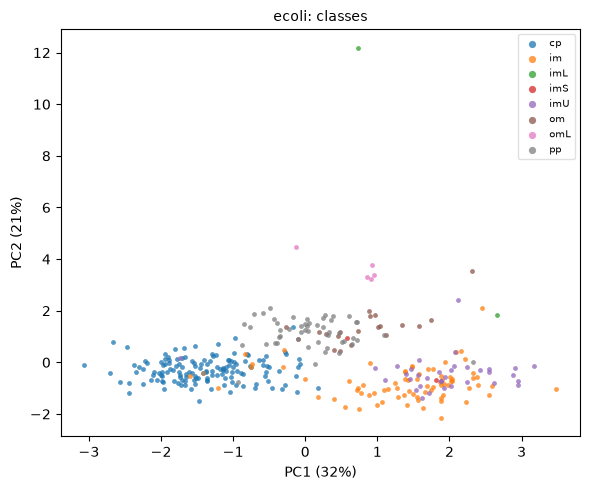

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/ecoli_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 8, label-free choice: 5


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari,ari
0,2,1782.202,0.321,0.600,-0.279,1.284,110,226,0.989,0.976,0.390
1,3,1402.518,0.381,0.293,0.087,1.269,79,151,1.000,1.000,0.674
2,4,1038.604,0.385,0.174,0.211,0.915,1,151,1.000,1.000,0.677
3,5,751.465,0.405,0.175,0.231,0.747,1,148,1.000,1.000,0.697
4,6,653.176,0.404,0.184,0.220,0.696,1,149,0.990,0.981,0.729
5,7,579.938,0.354,0.194,0.160,0.861,1,146,0.907,0.580,0.731
6,8,524.602,0.260,0.197,0.064,1.091,1,80,0.898,0.725,0.508
7,9,488.670,0.256,0.202,0.054,1.088,1,79,0.846,0.697,0.427
8,10,456.535,0.248,0.205,0.043,1.101,1,62,0.812,0.710,0.372


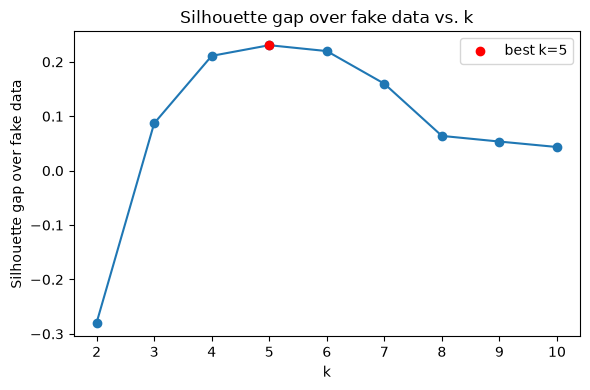

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/ecoli_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),583.586,10.0,0.009
K-Means,524.602,12.0,0.012


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

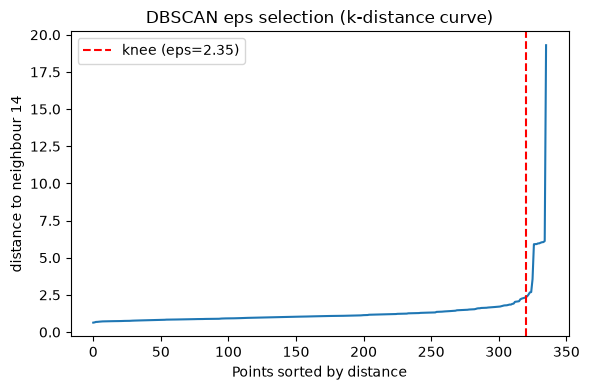

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/ecoli_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=0.809, min_samples=7, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,0.809,7,0.50,2,0.315,0.461,0.471,0.395,True
1,1.213,7,0.75,1,0.068,0.932,NaN,0.052,False
2,1.174,14,0.50,1,0.161,0.839,NaN,0.136,False
3,1.459,28,0.50,1,0.116,0.884,NaN,0.114,False
4,1.734,56,0.50,1,0.104,0.896,NaN,0.105,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=5, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,5,NaN,2,0.003,0.970,0.559,0.038,True
1,5,5.0,2,0.003,0.970,0.559,0.038,True
2,5,10.0,2,0.298,0.491,0.453,0.398,True
3,10,NaN,2,0.298,0.491,0.453,0.398,True
4,10,5.0,2,0.351,0.449,0.469,0.350,True
5,10,10.0,2,0.298,0.491,0.453,0.398,True
6,15,NaN,2,0.432,0.396,0.510,0.294,True
7,15,5.0,2,0.351,0.449,0.469,0.350,True
8,15,10.0,2,0.298,0.491,0.453,0.398,True
9,20,NaN,2,0.518,0.354,0.542,0.194,False


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=8, covariance_type=full, label-free: n_components=7, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,2875.5,3305.6,-5926.1,-6029.9
3,3035.3,3307.7,-5409.1,-1111.7
4,3774.9,3637.5,-5017.9,-947.1
5,3934.7,4173.6,-4855.4,3817.2
6,3933.0,4189.4,-4738.9,3778.7
7,3915.7,4222.9,-4606.6,3864.1
8,3901.1,4115.3,-4578.2,3946.3
9,3895.3,3923.5,-4515.5,3767.7
10,3916.2,3760.0,-4434.3,3926.4


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=8, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=8,8,0.000,0.208,0.236,1.135,-0.484,0.379,0.585,0.009,0.192
1,K-Means,n_clusters=8,8,0.000,0.238,0.260,1.091,-0.413,0.508,0.641,0.012,0.187
2,DBSCAN,"eps=0.809, min_samples=7",2,0.315,0.461,0.471,0.833,0.237,0.395,0.415,0.002,0.365
3,HDBSCAN,"min_cluster_size=5, min_samples=None",2,0.003,0.970,0.559,0.637,0.680,0.038,0.118,0.003,0.553
4,GMM,"n_components=8, covariance_type=full",8,0.000,0.384,0.157,2.024,-0.383,0.618,0.597,0.039,0.149
5,Spectral,"n_clusters=8, affinity=nearest_neighbors",8,0.000,0.185,0.231,1.305,-0.453,0.392,0.591,0.019,0.156


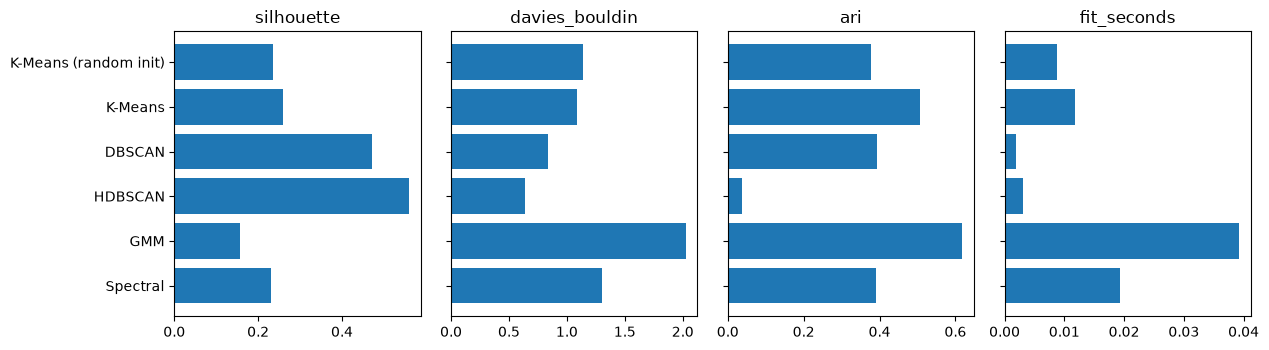

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/ecoli_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

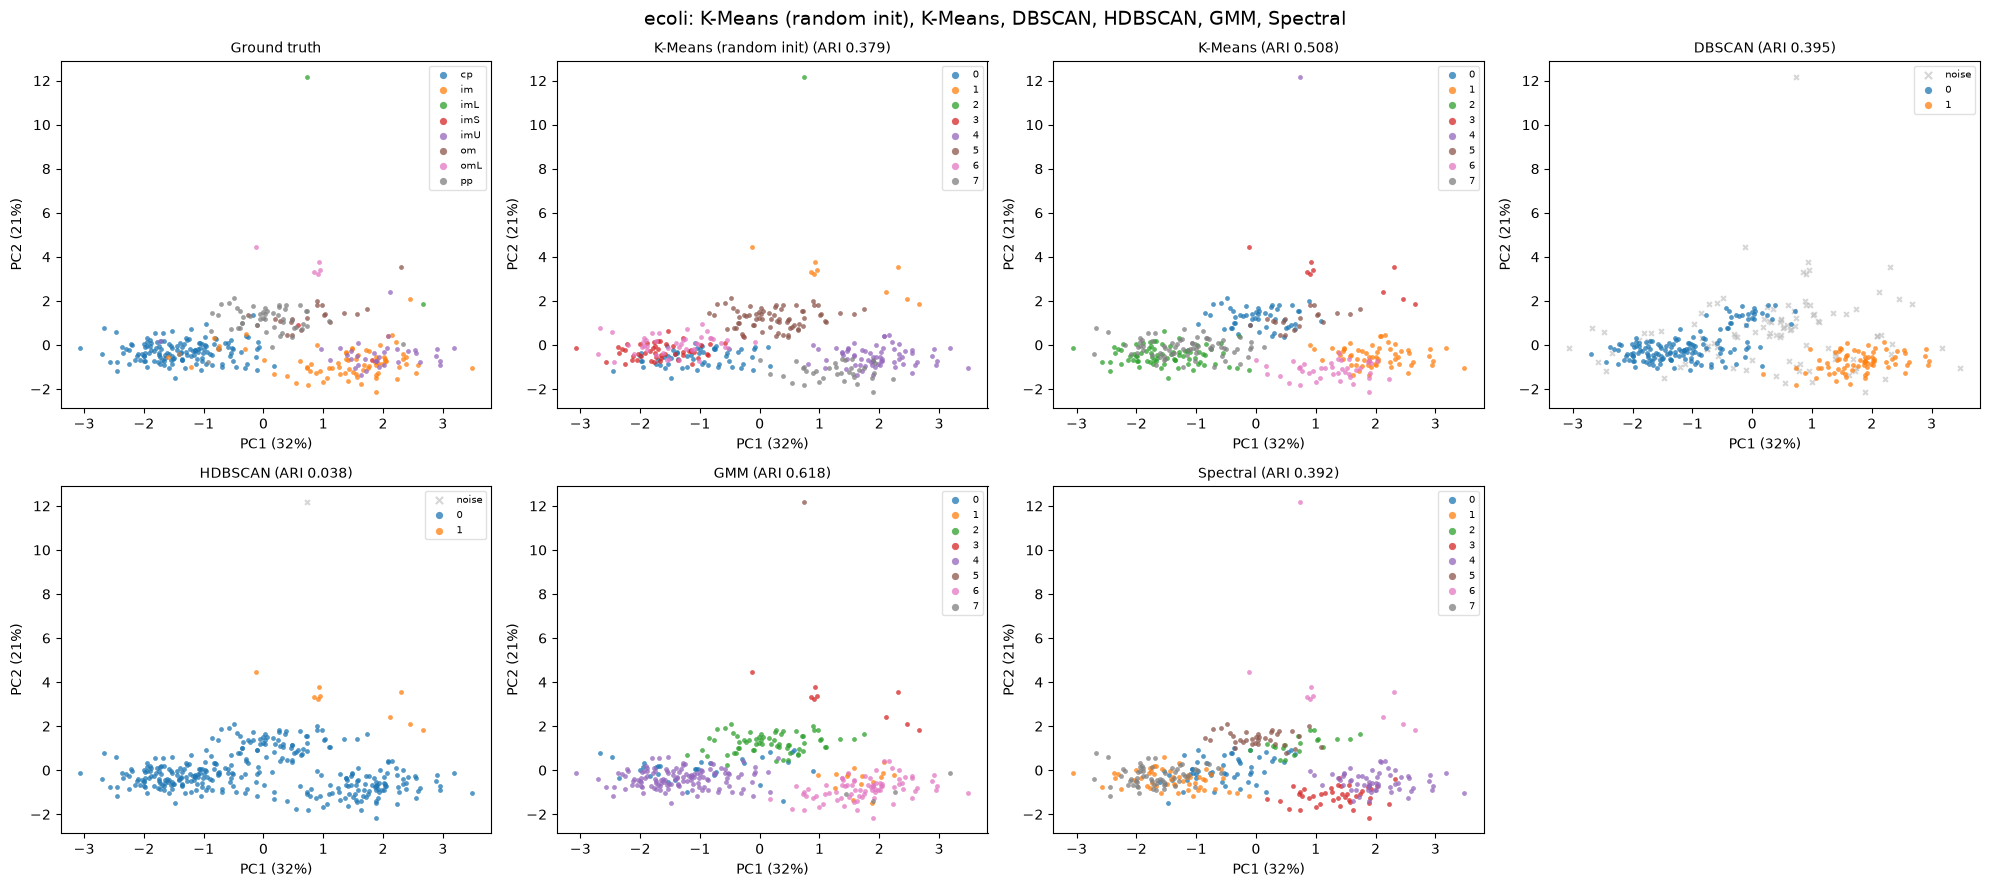

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/ecoli_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")